In [1]:
import numpy as np
from matplotlib import pyplot as plt

import primus_paleo as pp
from primus_paleo import (FluxHistory, Paleodetector, breakdown, compare_scenarios, plot_exposure_timeline,
                          plot_track_groups, slice_spectrum_etch, top_keys, track_total)

SUM = pp.TOTAL_NO_LIGHT_IONS

In [2]:
# Local time t [kyr] = 5970 - age [ka]: t = 0 at 5.97 Ma (base of the Main Halite), 640 at 5.33 Ma, 5970 today.
# Brine/water depth above the depositional surface (the free parameters of the scenario):
total_age_kyr_A = 5970
flood_time_A = 640.

D0      = 1000.   # at 5.97 Ma, when the sample forms                      [m]
D1      = 800.    # at 5.60 Ma, end of stage 1, before the drawdown        [m]
D_acme  = 300.    # at 5.55 Ma, stage-2 drawdown acme; kept until 5.33 Ma  [m]
D_flood = 2000.   # just after the Zanclean reflooding, 5.33 Ma            [m]
D_today = 1644.   # today (Leviathan-1 water depth)                        [m]

deep_water_base = {
    "initial_depth": D0,
    "initial_density_g_cm3": 1.2,
    "start_time_continuous_kyr": [0.,    0.,              370.,                 370.,  640.,   640.],
    "end_time_continuous_kyr":   [370.,  370.,            420.,                 640.,  5970.,  5970.],
    "rate_continuous":           [2.6,   (D1 - D0) / 370, (D_acme - D1) / 50,   2.7,   0.085,  (D_today - D_flood) / 5330],
    "density_continuous_g_cm3":  [2.16,  1.2,             1.2,                  2.3,   2.1,    1.03],
    "time_discrete_kyr":      [flood_time_A,     flood_time_A],
    "overburden_discrete":    [-D_acme,  D_flood],
    "density_discrete_g_cm3": [1.2,      1.03],
}

In [3]:
total_age_kyr_B = 5600
flood_time_B = 270

z_floor = 2000.    # depth of the brine surface below global sea level during the desiccation [m]
air_mwe = 10.33 * (np.exp(z_floor / 8400.) - 1.0)   # extra atmosphere above it, ~2.8 m.w.e. for 2 km
D_brine = 5.       # brine depth during the halite deposition, 5.60-5.55 Ma [m]
D_lake  = 20.      # lake depth during stage 3, Upper Gypsum / Lago-Mare, 5.55-5.33 Ma [m]
D_flood = 2000.    # seawater depth just after the Zanclean reflooding, 5.33 Ma [m]
D_today = 1644.    # today (Leviathan-1 water depth) [m]
H_halite, H_IE, H_AE, H_PQ = 960., 480., 230., 450.   # Main Halite, Interbedded Ev., Argillaceous Ev., Plio-Quaternary [m]

desiccation_base = {
    "initial_depth": air_mwe + 1.2 * D_brine, "initial_density_g_cm3": 1.0,   # extra air + brine, in m.w.e.
    "start_time_continuous_kyr": [0.,              50.,           180.,         270.,           270.],
    "end_time_continuous_kyr":   [50.,             180.,          270.,         5600.,          5600.],
    "rate_continuous":           [H_halite / 50.,  H_IE / 130.,   H_AE / 90.,   H_PQ / 5330.,   (D_today - D_flood) / 5330.],
    "density_continuous_g_cm3":  [2.16,            2.3,           2.3,          2.1,            1.03],
    "time_discrete_kyr":      [50.,              flood_time_B,    flood_time_B,      flood_time_B],
    "overburden_discrete":    [D_lake - D_brine, -D_lake,  -air_mwe,  D_flood],
    "density_discrete_g_cm3": [1.2,              1.2,      1.0,       1.03],
}

In [4]:
mineral_name = "Halite"

sample_area_cm2 = 1

In [5]:
flux_history_simple = FluxHistory(h_obs_km=1.)
flux_history_SN100 = FluxHistory(h_obs_km=1., events=[{"start_time_kyr": -total_age_kyr_B - 25., "template": {"kind": "SN", "distance_pc": 100.}}])

In [6]:
mineral = Paleodetector(mineral_name, total_age_kyr=total_age_kyr_B, overburden_history=desiccation_base, flux_history=flux_history_simple)
mineral_deepwater = Paleodetector(mineral_name, total_age_kyr=total_age_kyr_A, overburden_history=deep_water_base, flux_history=flux_history_simple)

mineral.describe_track_groups()     # which recoils count as heavy / medium / light in halite

Time grid: 629 nodes over 0-5600 kyr (105 uniform and breakpoint nodes, 524 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Halite, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 171.9 GeV in 90 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock 

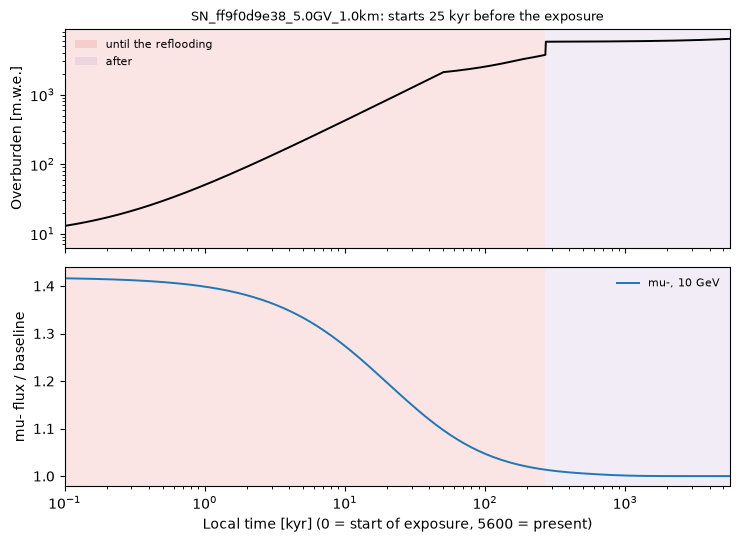

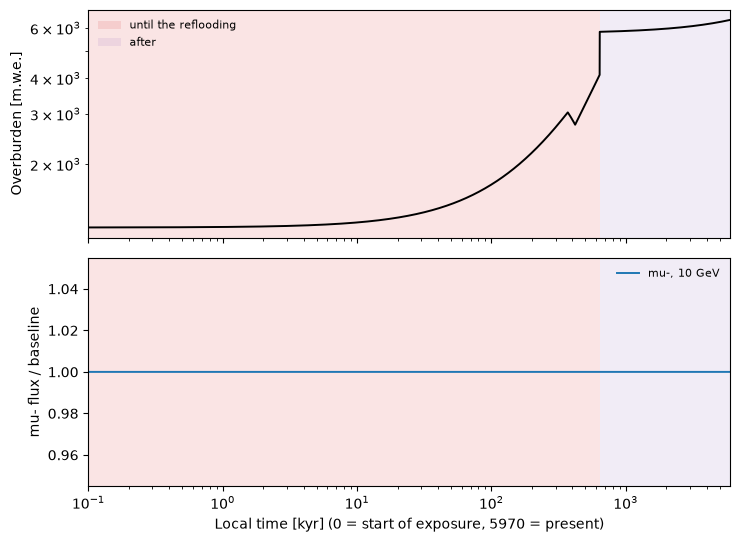

In [7]:
# Overburden and flux over each sample's exposure, with the integration windows; the SN100 history on the
# desiccation sample shows how much of the supernova reaches it (the title says when it starts)
for det, fh, flood in ((mineral, flux_history_SN100, flood_time_B), (mineral_deepwater, flux_history_simple, flood_time_A)):
    fig, (ax_ob, ax_fl) = plot_exposure_timeline(det, fh, windows={'until the reflooding': (0., flood),
                                                                   'after': (flood, det.total_age_kyr)})
    ax_fl.set_xscale('log')
    ax_fl.set_xlim(0.1, det.total_age_kyr)
    plt.show()

In [8]:
x_bins, radiogenic_B = mineral.integrate_radiogenic(nucleus='groups')
x_bins, radiogenic_A = mineral_deepwater.integrate_radiogenic(nucleus='groups')

In [9]:
window_B, window_A, window_post = [0., flood_time_B], [0., flood_time_A], [flood_time_B, total_age_kyr_B]

x_bins, tracks_simple = mineral.integrate_all_particles(exposure_window_kyr=window_B, nucleus='groups',
                                                        flux_history=flux_history_simple)
x_bins, tracks_simple_deepwater = mineral_deepwater.integrate_all_particles(exposure_window_kyr=window_A, nucleus='groups',
                                                                            flux_history=flux_history_simple)
x_bins, tracks_post = mineral.integrate_all_particles(exposure_window_kyr=window_post, nucleus='groups',
                                                      flux_history=flux_history_simple)

Time grid: 629 nodes over 0-5600 kyr (105 uniform and breakpoint nodes, 524 added where the overburden or flux change; 0 flux events, 0 excursions)


100%|██████████| 5/5 [01:49<00:00, 21.84s/it]

Time grid: 558 nodes over 0-5970 kyr (104 uniform and breakpoint nodes, 454 added where the overburden or flux change; 0 flux events, 0 excursions)



100%|██████████| 5/5 [01:00<00:00, 12.14s/it]

Time grid: 629 nodes over 0-5600 kyr (105 uniform and breakpoint nodes, 524 added where the overburden or flux change; 0 flux events, 0 excursions)



100%|██████████| 5/5 [00:29<00:00,  5.94s/it]


In [10]:
x_bins, neutrinos_B = mineral.integrate_atmospheric_neutrinos(exposure_window_kyr=window_B, nucleus='groups',
                                                              flux_history=flux_history_simple)
x_bins, neutrinos_A = mineral_deepwater.integrate_atmospheric_neutrinos(exposure_window_kyr=window_A, nucleus='groups',
                                                                        flux_history=flux_history_simple)

Time grid: 629 nodes over 0-5600 kyr (105 uniform and breakpoint nodes, 524 added where the overburden or flux change; 0 flux events, 0 excursions)
Neutrino secondaries made in the mineral (no StdRock runs for ['nu_mu', 'anti_nu_mu', 'nu_e', 'anti_nu_e']).
Neutrinos nu_mu (Halite runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.0142
Neutrinos anti_nu_mu (Halite runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.0072
Neutrinos nu_e (Halite runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.017
Neutrinos anti_nu_e (Halite runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.0102
Time grid: 558 nodes over 0-5970 kyr (104 uniform and breakpoint nodes, 454 added where the overburden or flux change; 0 flux events, 0 excursions)
Neutrino secondaries made in the mineral (no StdRock runs for ['nu_mu', 'anti_nu_mu', 'nu_e', 'anti_nu_e']).
Neutrinos nu_mu (Halite runs): 75 runs, bias 1e+08, biased interactions per primary up to 0

In [11]:
x_bins, tracks_SN100 = mineral.integrate_all_particles(exposure_window_kyr=window_B, nucleus='groups',
                                                       flux_history=flux_history_SN100)

Time grid: 626 nodes over 0-5600 kyr (174 uniform and breakpoint nodes, 452 added where the overburden or flux change; 1 flux events, 0 excursions)


100%|██████████| 5/5 [01:42<00:00, 20.60s/it]


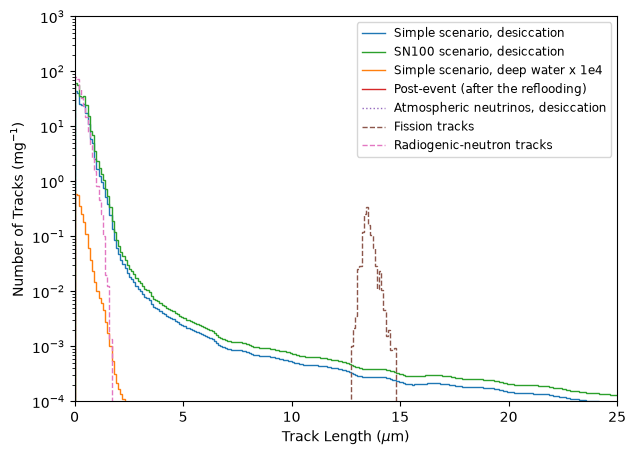

In [12]:
fig, ax = plt.subplots(figsize=[7, 5])
x_um = x_bins / 1000

ax.stairs(track_total(tracks_simple), x_um, label='Simple scenario, desiccation')
ax.stairs(track_total(tracks_SN100), x_um, color='C2', label='SN100 scenario, desiccation')
ax.stairs(track_total(tracks_simple_deepwater) * 1e4, x_um, color='C1', label='Simple scenario, deep water x 1e4')
ax.stairs(track_total(tracks_post), x_um, color='C3', label='Post-event (after the reflooding)')
ax.stairs(track_total(neutrinos_B), x_um, color='C4', linestyle='dotted', label='Atmospheric neutrinos, desiccation')

ax.stairs(radiogenic_B['fission_fragments'][SUM], x_um, color='C5', linestyle='dashed', label='Fission tracks')
ax.stairs(radiogenic_B['fission_n'][SUM] + radiogenic_B['alpha_n'][SUM], x_um, color='C6', linestyle='dashed',
          label='Radiogenic-neutron tracks')

ax.set_xlabel(r"Track Length ($\mu$m)")
ax.set_ylabel(r"Number of Tracks (mg$^{-1}$)")
ax.set_yscale("log")
ax.set_ylim(1e-4, 1e3)
ax.set_xlim(0, 25)
ax.legend(fontsize='small')
plt.show()

In [13]:
n = {label: np.sum(track_total(result)) for label, result in (
    ('cosmic B', tracks_simple), ('cosmic A', tracks_simple_deepwater), ('SN100 B', tracks_SN100),
    ('nu B', neutrinos_B), ('nu A', neutrinos_A), ('post B', tracks_post))}
print(f"Tracks per mg, desiccation (0-{flood_time_B} kyr): cosmic rays {n['cosmic B']:.3g}, neutrinos {n['nu B']:.3g}; "
      f"after the reflooding {n['post B']:.3g}")
print(f"Tracks per mg, deep water  (0-{flood_time_A:g} kyr): cosmic rays {n['cosmic A']:.3g}, neutrinos {n['nu A']:.3g}")
if n['cosmic A'] > 0:
    print(f"Desiccation / deep water, cosmic rays: {n['cosmic B'] / n['cosmic A']:.3g}")
else:
    print("Deep water: no cosmic-ray tracks (overburden beyond the StdRock depth tables): neutrinos only.")
print(f"Desiccation / deep water, cosmic rays + neutrinos: {(n['cosmic B'] + n['nu B']) / (n['cosmic A'] + n['nu A']):.3g}")
print(f"SN100 excess in the desiccation sample: {n['SN100 B'] / n['cosmic B'] - 1:+.2%}")

Tracks per mg, desiccation (0-270 kyr): cosmic rays 208, neutrinos 2.21e-06; after the reflooding 0
Tracks per mg, deep water  (0-640 kyr): cosmic rays 0.000224, neutrinos 5.24e-06
Desiccation / deep water, cosmic rays: 9.27e+05
Desiccation / deep water, cosmic rays + neutrinos: 9.06e+05
SN100 excess in the desiccation sample: +40.23%


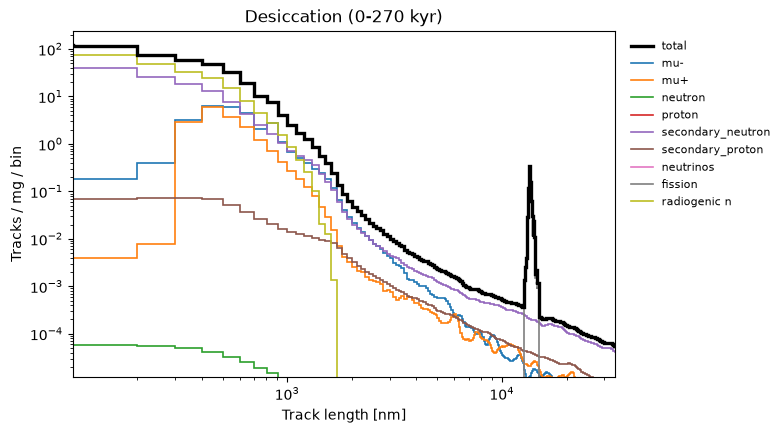

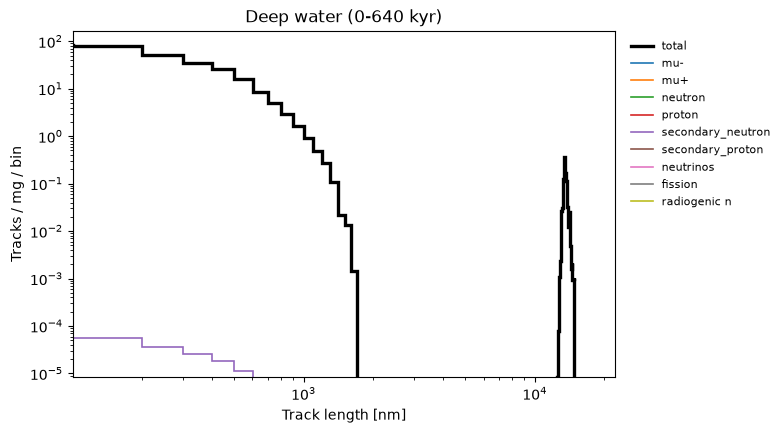

In [14]:
sources_B = breakdown(cosmic=tracks_simple, neutrinos=neutrinos_B, radiogenic=radiogenic_B)
sources_A = breakdown(cosmic=tracks_simple_deepwater, neutrinos=neutrinos_A, radiogenic=radiogenic_A)
keys = [k for k in sources_B if k != 'total']

for label, sources in (('Desiccation (0-270 kyr)', sources_B), ('Deep water (0-640 kyr)', sources_A)):
    fig, ax = plot_track_groups(sources, x_bins, style='lines', keys=keys, total='total', logy=True, y_decades=7)
    ax.set_title(label)
    plt.show()

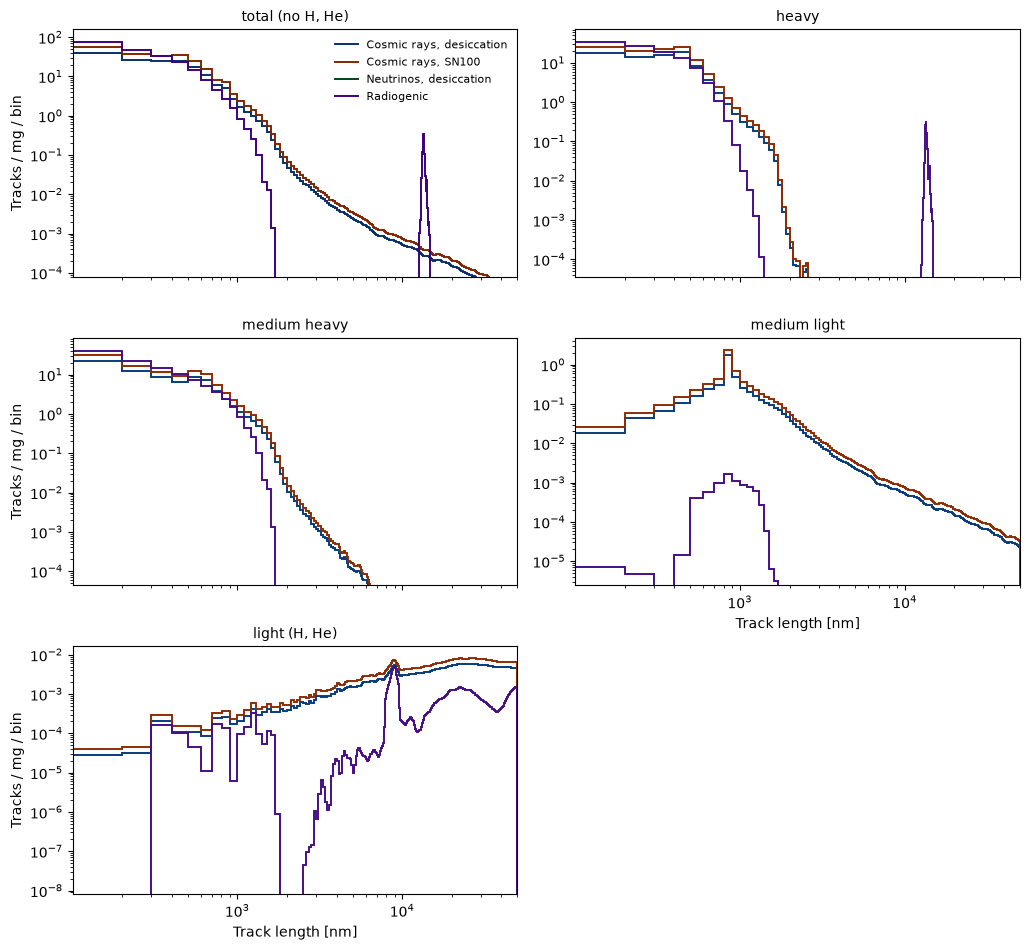

In [15]:
fig, axes = plot_track_groups({'Cosmic rays, desiccation': tracks_simple['total'],
                               'Cosmic rays, SN100': tracks_SN100['total'],
                               'Neutrinos, desiccation': neutrinos_B['total'],
                               'Radiogenic': radiogenic_B['total']},
                              x_bins, style='panels', logy=True, y_decades=6)
plt.show()

Time grid: 629 nodes over 0-5600 kyr (105 uniform and breakpoint nodes, 524 added where the overburden or flux change; 0 flux events, 0 excursions)


100%|██████████| 5/5 [01:06<00:00, 13.27s/it]


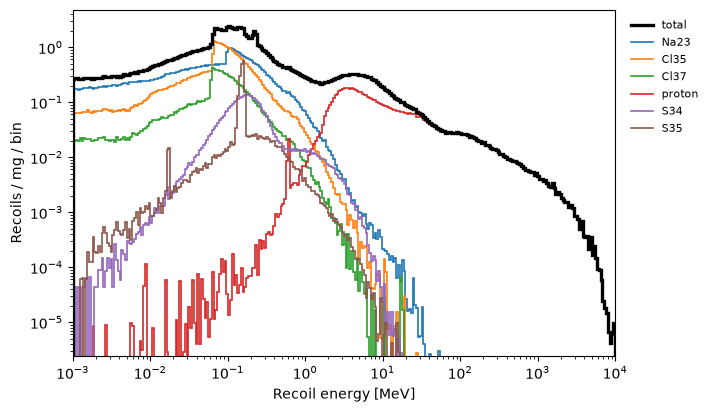

In [17]:
e_bins, recoils_B = mineral.integrate_all_particles(exposure_window_kyr=window_B, nucleus='all',
                                                   observable='recoil_energy', flux_history=flux_history_simple)
nuclides = recoils_B['total']
heaviest = top_keys(nuclides, 6)
fig, ax = plot_track_groups(nuclides, e_bins, style='lines', keys=heaviest, total='total', observable='recoil_energy',
                            logy=True, y_decades=6)
plt.show()

In [18]:
# Every etched pit (expected numbers): the microscope resolution is the later observation step. The etching response
# of the sample is computed once (a few seconds) and shared by every spectrum, so differences carry no Monte Carlo noise.
density = mineral.config["density_g_cm3"]
etch = dict(sample_area_cm2=sample_area_cm2, sample_density_g_cm3=density, etch_type='HF', x_bins=x_bins)

sliced_bkg = slice_spectrum_etch(radiogenic_B['total'][SUM], **etch)
sliced_bkg_deepwater = slice_spectrum_etch(radiogenic_A['total'][SUM] + track_total(neutrinos_A), **etch)
sliced_simple = slice_spectrum_etch(track_total(tracks_simple) + track_total(neutrinos_B), **etch)
sliced_SN100 = slice_spectrum_etch(track_total(tracks_SN100) + track_total(neutrinos_B), **etch)
sliced_simple_deepwater = slice_spectrum_etch(track_total(tracks_simple_deepwater), **etch)

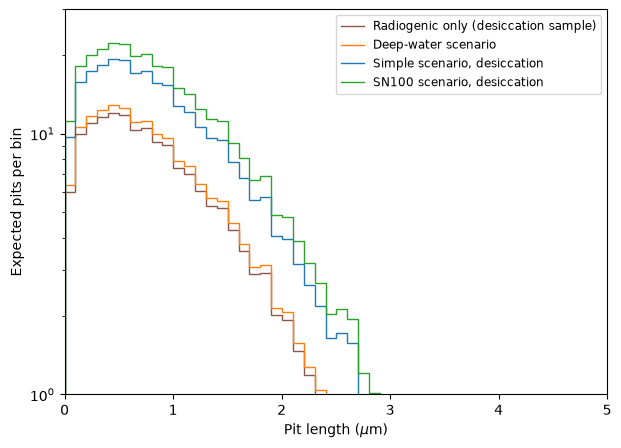

all pits: simple 273.7, SN100 excess 46.05 = 2.78 sigma (Poisson, counts only)
pits 2-50 um: simple 23.3, SN100 excess 5.00 = 1.04 sigma (Poisson, counts only)


In [19]:
fig, ax = plt.subplots(figsize=[7, 5])

ax.stairs(sliced_bkg, x_um, color='C5', label='Radiogenic only (desiccation sample)')
ax.stairs(sliced_simple_deepwater + sliced_bkg_deepwater, x_um, color='C1', label='Deep-water scenario')
ax.stairs(sliced_simple + sliced_bkg, x_um, color='C0', label='Simple scenario, desiccation')
ax.stairs(sliced_SN100 + sliced_bkg, x_um, color='C2', label='SN100 scenario, desiccation')

ax.set_xlabel(r"Pit length ($\mu$m)")
ax.set_ylabel(r"Expected pits per bin")
ax.set_yscale("log")
ax.set_ylim(1e0, 3e1)
ax.set_xlim(0, 5)
ax.legend(fontsize='small')
plt.show()

# The SN100 scenario against the simple one, both with the same neutrinos and radiogenic background: all pits, and
# the long pits only (where the cosmic-ray tracks stand out more)
background = radiogenic_B['total'][SUM] + track_total(neutrinos_B)
spectra = {'simple': track_total(tracks_simple) + background, 'SN100': track_total(tracks_SN100) + background}
for size_range in (None, (2000., 50000.)):
    result = compare_scenarios(spectra, 'simple', sample_area_cm2, density, size_range_nm=size_range, x_bins=x_bins)
    where = 'all pits' if size_range is None else f'pits {size_range[0] / 1e3:g}-{size_range[1] / 1e3:g} um'
    print(f"{where}: simple {result['simple']['n']:.1f}, SN100 excess {result['SN100']['excess']:.2f} "
          f"= {result['SN100']['significance']:.2f} sigma (Poisson, counts only)")